# Cleaning the Fermi-LAT light curves

Stage: data acquisition and cleaning (UCL DSS Project Labs).

**Source:** Fermi-LAT Light Curve Repository (LCR), 3-day bins, photon flux, fixed photon index, TS >= 4, downloaded via NASA's own API (snapshot dated 17 Nov 2026).
**This notebook** loads the cleaned file for the selected sources and shows what it looks like. The cleaning itself is done by `src/clean_lcr.py`; the combined file is made by `src/combine_selected.py`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../cleaned/cleaned_min300.csv")
sel = pd.read_csv("../cleaned/selected_sources.csv")
print(df.shape, "rows;", df["source"].nunique(), "sources")

(341129, 10) rows; 478 sources


## First rows

In [2]:
df.head()

,source,time_MJD,ts,flux,flux_error,photon_index,gap_days,F_q,flux_norm,flux_error_norm
0,4FGL_J0001.5+2113,54705.5,4.96,7.060000e-08,4.230000e-08,2.55,NaN,8.310000e-08,0.849579,0.509025
1,4FGL_J0001.5+2113,54966.5,6.81,8.220000e-08,4.490000e-08,2.55,261.0,8.310000e-08,0.989170,0.540313
2,4FGL_J0001.5+2113,54990.5,7.94,1.240000e-07,5.710000e-08,2.55,24.0,8.310000e-08,1.492180,0.687124
3,4FGL_J0001.5+2113,55014.5,4.60,6.160000e-08,3.580000e-08,2.55,24.0,8.310000e-08,0.741276,0.430806
4,4FGL_J0001.5+2113,55101.5,4.93,8.880000e-08,5.140000e-08,2.55,87.0,8.310000e-08,1.068590,0.618532


## Column types and missing values

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 341129 entries, 0 to 341128
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   source           341129 non-null  object 
 1   time_MJD         341129 non-null  float64
 2   ts               341129 non-null  float64
 3   flux             341129 non-null  float64
 4   flux_error       341129 non-null  float64
 5   photon_index     341129 non-null  float64
 6   gap_days         340651 non-null  float64
 7   F_q              341129 non-null  float64
 8   flux_norm        341129 non-null  float64
 9   flux_error_norm  341129 non-null  float64
dtypes: float64(9), object(1)
memory usage: 26.0+ MB


## Summary statistics

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
time_MJD,341129.0,5.796684e+04,1.921142e+03,5.468450e+04,5.629250e+04,5.793050e+04,5.961350e+04,61350.500000
ts,341129.0,4.083925e+01,2.261718e+02,4.000000e+00,6.730000e+00,1.172000e+01,2.629000e+01,51890.300000
flux,341129.0,2.091891e-07,1.724808e-06,3.040000e-09,4.600000e-08,8.000000e-08,1.490000e-07,0.000098
flux_error,341129.0,5.191029e-08,3.602121e-07,0.000000e+00,2.610000e-08,3.800000e-08,5.450000e-08,0.000057
photon_index,341129.0,2.135598e+00,3.194957e-01,6.300000e-01,1.950000e+00,2.160000e+00,2.330000e+00,3.800000
gap_days,340651.0,9.281857e+00,1.686235e+01,3.000000e+00,3.000000e+00,3.000000e+00,9.000000e+00,1188.000000
F_q,341129.0,7.740661e-08,1.607367e-07,5.770000e-09,3.200000e-08,4.905000e-08,7.030000e-08,0.000002
flux_norm,341129.0,3.295371e+00,4.544278e+01,8.919900e-02,1.177790e+00,1.668830e+00,2.495190e+00,5801.920000
flux_error_norm,341129.0,9.775362e-01,9.215958e+00,0.000000e+00,6.100760e-01,7.900000e-01,1.024850e+00,1960.260000


## Cleaning decisions

| # | Decision | Why |
|---|----------|-----|
| 1 | Keep only bins with TS >= 4 | Below this the LCR gives only an upper limit, not a flux (detection threshold; as in the paper) |
| 2 | Drop flux <= 0 and non-finite flux errors | Not physical / unusable |
| 3 | Drop flux > 1e-4 ph cm^-2 s^-1 | Paper's cap; likely fit artefacts. May remove real flares, so the team should decide whether to flag instead of delete |
| 4 | Drop bins where the fit did not converge | Our addition; unreliable fluxes |
| 5 | No imputation of missing bins | Gaps are kept and recorded in `gap_days` |
| 6 | Flux error = (upper - lower) / 2 | The API gives asymmetric bounds; we use a symmetric error |
| 7 | Normalise by quiescent flux `F_q` = median of the lowest 30% of training-period fluxes | Puts sources of different brightness on one scale |
| 8 | Training period = before MJD 59910 (paper default), needs >= 30 points | Prevents test-period information leaking into `F_q`. **Cut date not yet agreed with the team** |
| 9 | Only sources with >= 300 detections are in this file | Faint sources are mostly upper limits. **Threshold not yet agreed with the team** |

## Detections per source

count     478.000000
mean      713.658996
std       442.998108
min       301.000000
25%       385.500000
50%       551.000000
75%       886.000000
max      2178.000000
Name: n_kept, dtype: float64


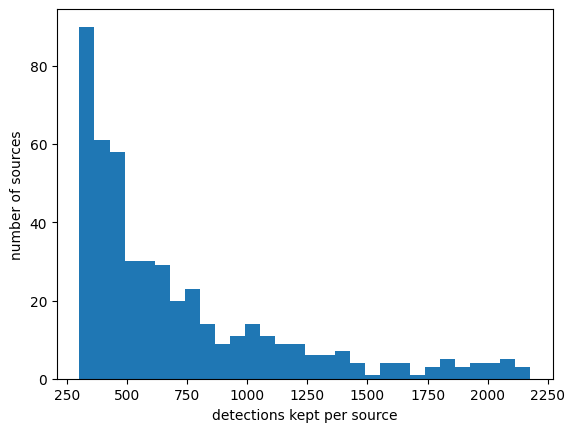

In [5]:
print(sel["n_kept"].describe())
ax = sel["n_kept"].plot.hist(bins=30)
ax.set_xlabel("detections kept per source"); ax.set_ylabel("number of sources")
plt.show()

## Example cleaned light curve

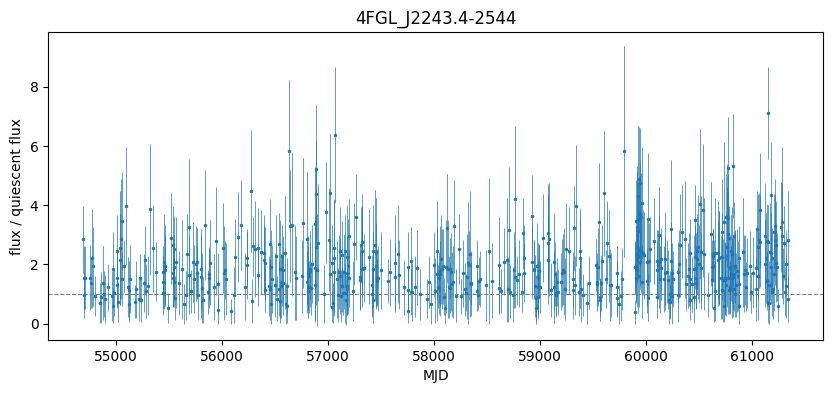

In [6]:
src = sel.sort_values("n_kept").iloc[len(sel) // 2]["source"]
d = df[df["source"] == src]
fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(d["time_MJD"], d["flux_norm"], yerr=d["flux_error_norm"], fmt=".", ms=3, lw=0.5)
ax.axhline(1, color="grey", ls="--", lw=0.8)
ax.set_xlabel("MJD"); ax.set_ylabel("flux / quiescent flux"); ax.set_title(src)
plt.show()

## Gaps between kept bins

In [7]:
print(df["gap_days"].describe())
print("share of gaps that are exactly 3 days:", (df["gap_days"] == 3).mean().round(3))

count    340651.000000
mean          9.281857
std          16.862351
min           3.000000
25%           3.000000
50%           3.000000
75%           9.000000
max        1188.000000
Name: gap_days, dtype: float64
share of gaps that are exactly 3 days: 0.59
